<a href="https://colab.research.google.com/github/JanethGrimaldo/AI/blob/main/AF6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

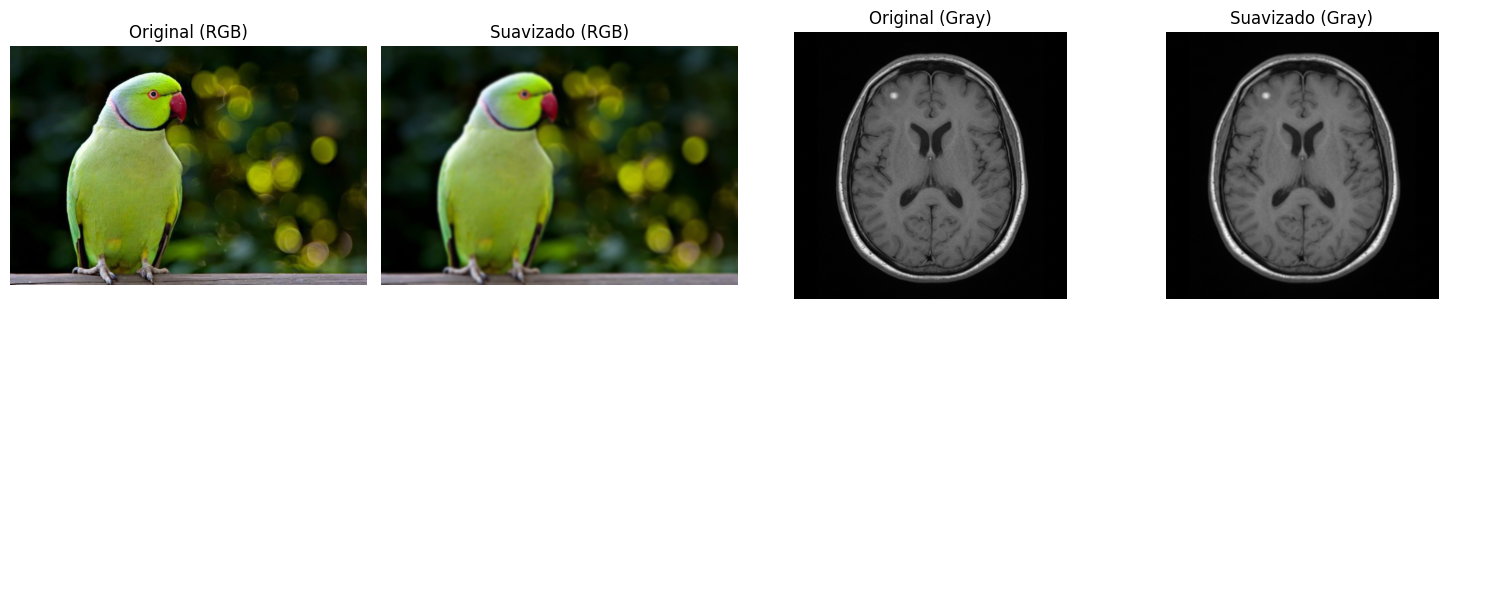

In [4]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img_bgr = cv2.imread("ave.png")
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

img_gray = cv2.imread("4.jpg",0)

k_gauss = (11,11)
blur_rgb= cv2.GaussianBlur(img_rgb, k_gauss, 0)

blur_gray= cv2.GaussianBlur(img_gray, k_gauss, 0)

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
axes = axes.ravel() # Flatten the 2D array of axes to a 1D array

axes[0].imshow(img_rgb)
axes[0].set_title("Original (RGB)")
axes[1].imshow(blur_rgb)
axes[1].set_title("Suavizado (RGB)")
axes[2].imshow(img_gray, cmap="gray")
axes[2].set_title("Original (Gray)")
axes[3].imshow(blur_gray, cmap="gray")
axes[3].set_title("Suavizado (Gray)")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

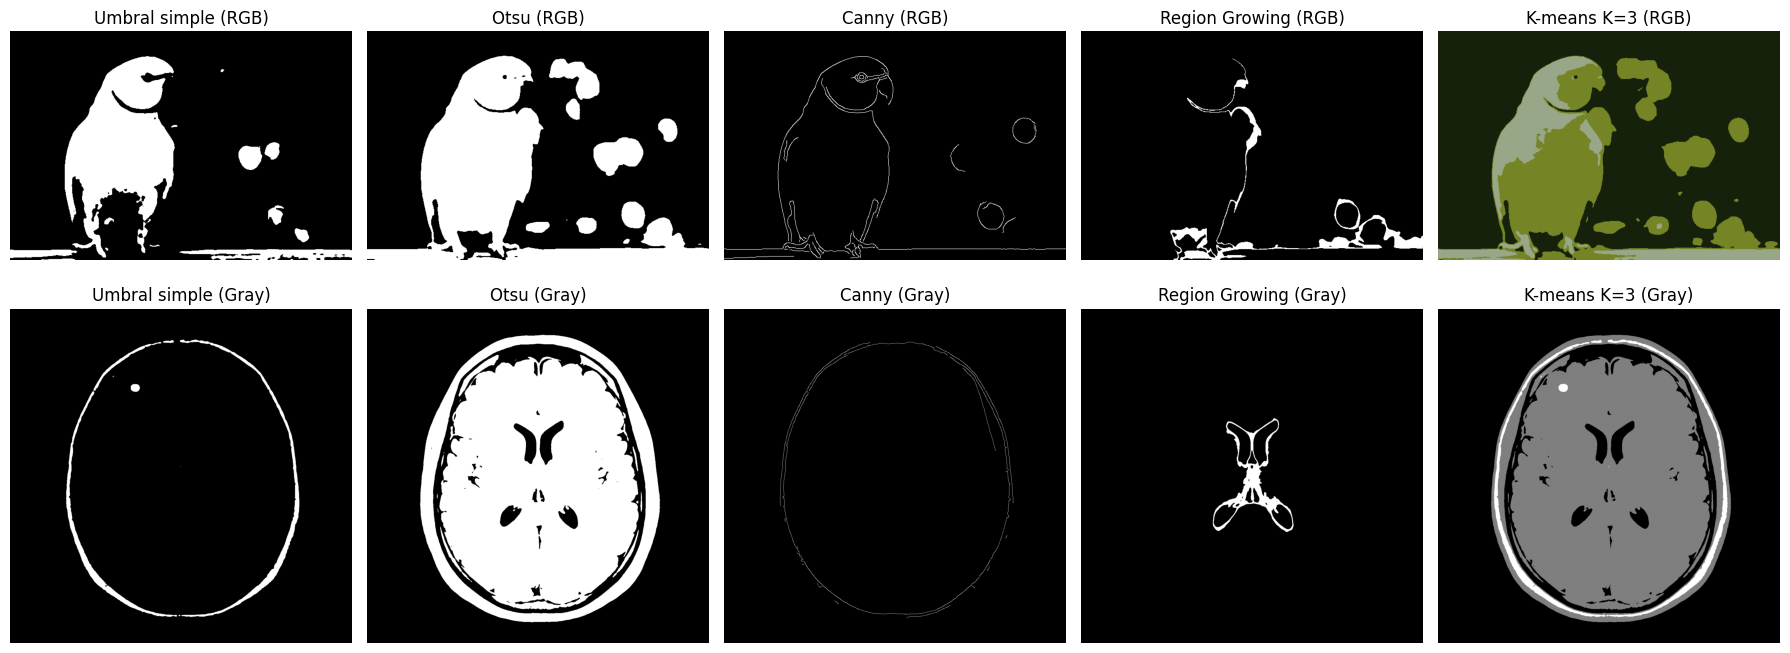

In [6]:
blur_rgb_gray = cv2.cvtColor(blur_rgb, cv2.COLOR_RGB2GRAY)

umbral_rgb = 127
umbral_gray = 127
_, thresh_rgb = cv2.threshold(blur_rgb_gray, umbral_rgb, 255, cv2.THRESH_BINARY)
_, thresh_gray = cv2.threshold(blur_gray, umbral_gray, 255, cv2.THRESH_BINARY)

_, otsu_rgb = cv2.threshold(blur_rgb_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, otsu_gray = cv2.threshold(blur_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

t1_rgb, t2_rgb = 50, 150
t1_gray, t2_gray = 50, 150
canny_rgb = cv2.Canny(blur_rgb, t1_rgb, t2_rgb)
canny_gray = cv2.Canny(blur_gray, t1_gray, t2_gray)

def region_growing(imagen, semilla, tolerancia):
    alto, ancho = imagen.shape
    mascara = np.zeros((alto, ancho), dtype=np.uint8)
    visitado = np.zeros((alto, ancho), dtype=bool)

    y0, x0 = semilla
    valor_semilla = float(imagen[y0, x0])
    pila = [(y0, x0)]
    visitado[y0, x0] = True

    while pila:
        y, x = pila.pop()
        if abs(float(imagen[y, x]) - valor_semilla) <= tolerancia:
            mascara[y, x] = 255
            for dy in (-1, 0, 1):
                for dx in (-1, 0, 1):
                    ny, nx = y + dy, x + dx
                    if 0 <= ny < alto and 0 <= nx < ancho and not visitado[ny, nx]:
                        visitado[ny, nx] = True
                        pila.append((ny, nx))
    return mascara

# Using the center of the RGB image (approx. size 463x693) as seed
semilla_rgb = (230, 345)    # (fila_y, col_x) en ave.png
tol_rgb = 15
rg_rgb = region_growing(blur_rgb_gray, semilla_rgb, tol_rgb)

# Using the center of the grayscale image (approx. size 1321x1351) as seed
semilla_gray = (660, 675)   # (fila_y, col_x) en 4.jpg
tol_gray = 15
rg_gray = region_growing(blur_gray, semilla_gray, tol_gray)

K = 3
criterio = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)

datos_rgb = blur_rgb.reshape((-1, 3)).astype(np.float32)
_, etiq_rgb, cent_rgb = cv2.kmeans(datos_rgb, K, None, criterio, 10, cv2.KMEANS_RANDOM_CENTERS)
kmeans_rgb = np.uint8(cent_rgb)[etiq_rgb.flatten()].reshape(blur_rgb.shape)

datos_gray = blur_gray.reshape((-1, 1)).astype(np.float32)
_, etiq_gray, cent_gray = cv2.kmeans(datos_gray, K, None, criterio, 10, cv2.KMEANS_RANDOM_CENTERS)
kmeans_gray = np.uint8(cent_gray)[etiq_gray.flatten()].reshape(blur_gray.shape)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

fila_rgb = [
    (thresh_rgb, "Umbral simple (RGB)", "gray"),
    (otsu_rgb, "Otsu (RGB)", "gray"),
    (canny_rgb, "Canny (RGB)", "gray"),
    (rg_rgb, "Region Growing (RGB)", "gray"),
    (kmeans_rgb, f"K-means K={K} (RGB)", None),
]

fila_gray = [
    (thresh_gray, "Umbral simple (Gray)", "gray"),
    (otsu_gray, "Otsu (Gray)", "gray"),
    (canny_gray, "Canny (Gray)", "gray"),
    (rg_gray, "Region Growing (Gray)", "gray"),
    (kmeans_gray, f"K-means K={K} (Gray)", "gray"),
]

for col, (im, tit, cmap) in enumerate(fila_rgb):
    axes[0, col].imshow(im, cmap=cmap)
    axes[0, col].set_title(tit)
    axes[0, col].axis("off")

for col, (im, tit, cmap) in enumerate(fila_gray):
    axes[1, col].imshow(im, cmap=cmap)
    axes[1, col].set_title(tit)
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()